# Add mouse disease cells to the five-species SATURN experiment

Run this notebook **locally**. It queries the public CELLxGENE API, downloads a pinned H5AD, extracts raw study counts, audits QC and confounding, and writes sparse five-species manifests plus donor-held-out mouse inputs. **The existing atlases contain normalized expression, not raw counts.** Model inputs therefore use an explicit common per-cell sum of 10,000; study raw counts are retained separately. This is a normalized-expression compatibility experiment, and SATURN's inherited count likelihood cannot be interpreted as a calibrated raw-count model. It does not train models or contact cloud services.

Default: **RDEB mouse paw skin**, 9,816 cells, two wild-type and two Col7a1-knockout mice. Alternative: **post-influenza mouse lung**, 123,154 cells, 23 exposed and only two healthy donors. Both are exploratory; the skin pilot is the smaller download (109 MB versus 1.61 GB).

Read [the experiment design](DISEASE_EXPERIMENT.md) for the controls, outcome definitions, training settings and limitations. The question is whether disease-associated states survive integration **within a tissue and cell type, using the existing cell holdout**, while healthy external controls align sensibly. A separate cluster alone cannot establish this.

Install `notebooks/local/requirements.txt` in a local kernel, or use the repository's existing `saturn` environment. The raw downloads are cached under `data/disease_pilot/downloads`; derived files go under `out/disease_pilot`. Run All defaults to one dataset and materializes fold 0; all donor fold assignments are saved for an optional later experiment. The first run uses the full augmented population followed by the existing 90/10 cell split.

In [1]:
from pathlib import Path
import gc
import json
import os
import sys
import platform
from datetime import datetime, timezone

import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/human_monkey_mouse_frog_fish.csv').is_file())
sys.path.insert(0, str(ROOT))
from disease_pilot.preparation import (
    resolve_dataset, download_dataset, prepare_external, materialize_experiment,
    sha256, write_json, assert_counts,
)

# Change the preset to run the second study as a separate experiment.
PRESET = os.environ.get('DISEASE_PRESET', 'rdeb_skin')
assert PRESET in {'rdeb_skin', 'post_flu_lung'}
LIVE_API = os.environ.get('DISEASE_LIVE_API', '1') == '1'
SEED = 0
MIN_GENES = 200
MAX_MITO_FRACTION = .25
MAX_CELLS_PER_DONOR_TYPE = None  # optional computational cap; does not balance conditions
MATERIALIZE_FOLDS = (0,)  # skin: (0, 1) for both; lung also has two folds (only 2 healthy donors)
MANIFEST = ROOT / 'data/human_monkey_mouse_frog_fish.csv'
DOWNLOADS = ROOT / 'data/disease_pilot/downloads'
DEST = ROOT / 'out/disease_pilot' / PRESET / 'prep_seed0'
DEST.mkdir(parents=True, exist_ok=True)
SNAPSHOT_PATH = ROOT / 'notebooks/local/cellxgene_candidates.json'
SNAPSHOT = json.loads(SNAPSHOT_PATH.read_text())
ORGAN = {'rdeb_skin': 'skin', 'post_flu_lung': 'lung'}[PRESET]
print('Kernel:', sys.executable)
print('Preset:', PRESET, '| Live metadata API:', LIVE_API, '| Destination:', DEST)


Kernel: /home/darcy/miniconda3/envs/saturn/bin/python
Preset: rdeb_skin | Live metadata API: True | Destination: /home/darcy/projects/SATURN-unsupervised/out/disease_pilot/rdeb_skin/prep_seed0


## 1. Confirm the five atlas inputs

“Monkey” here is the mouse lemur, *Microcebus murinus*. These are the current local inputs, totaling 148,727 cells. They retain `organ` and `cellType`, but **no donor or assay columns**. The atlas reference cannot support a donor-generalization claim of its own. Atlases can also contain batch effects; their construction does not guarantee their absence.

In [2]:
manifest = pd.read_csv(MANIFEST)
atlas_rows = []
mouse_genes = None
for row in manifest.itertuples():
    atlas = ad.read_h5ad(ROOT / row.path, backed='r')
    sample = atlas.X[:min(32, atlas.n_obs)].data
    atlas_rows.append({'species': row.species, 'cells': atlas.n_obs, 'genes': atlas.n_vars,
                       'sample_fraction_noninteger': float(np.mean(np.abs(sample - np.rint(sample)) > 1e-5)),
                       'has_donor': 'donor_id' in atlas.obs,
                       'has_assay': 'assay' in atlas.obs,
                       'organs': ', '.join(sorted(atlas.obs.organ.astype(str).unique()))})
    if row.species == 'm_musculus':
        mouse_genes = atlas.var_names.copy()
        mouse_reference_obs = atlas.obs.copy()
    atlas.file.close()
atlas_audit = pd.DataFrame(atlas_rows)
assert len(manifest) == 5 and manifest.species.is_unique
assert int(atlas_audit.cells.sum()) == 148727
atlas_audit.to_csv(DEST / 'atlas_audit.csv', index=False)
display(atlas_audit)
print('Mouse reference:', mouse_reference_obs.loc[mouse_reference_obs.organ == ORGAN, 'cellType'].value_counts().loc[lambda x: x > 0].to_dict())


,species,cells,genes,sample_fraction_noninteger,has_donor,has_assay,organs
0,h_sapiens,51881,19504,0.999988,False,False,"bladder, blood, colon, eye, fat, gut, heart, k..."
1,m_musculus,26947,15437,1.000000,False,False,"bladder, colon, fat, heart, kidney, liver, lun..."
2,m_murinus,38276,13495,0.999795,False,False,"bladder, blood, bone, brain, colon, diaphragm,..."
3,x_laevis,29437,30871,0.999977,False,False,"bladder, brain, eye, gut, heart, kidney, liver..."
4,d_rerio,2186,12468,1.000000,False,False,whole


Mouse reference: {'keratinocyte': 200, 'basal': 200, 'epidermal': 200, 'stem': 171, 'T': 62}


## 2. Review the selected public datasets and resolve a pinned version

The snapshot contains four reviewed candidates, including the two rejected/deferred alternatives. Dataset IDs refer to mutable latest releases; **dataset version IDs** pin the files used here. Every live run verifies that the pinned API asset still matches the reviewed metadata. Set `DISEASE_LIVE_API=0` only to reuse the checked-in metadata and cached download offline.

The liver option has pooled condition groups rather than independent per-animal identifiers. The spinal injury option has better animal replication, but spinal cord/microglia are absent from the existing mammalian inputs, confounding disease with a new tissue and cell identity. Neither is the default.

In [3]:
candidate_rows = []
for name, candidate in SNAPSHOT['datasets'].items():
    asset = next(a for a in candidate['assets'] if a['filetype'] == 'H5AD')
    candidate_rows.append({'preset': name, 'cells': candidate['cell_count'],
                           'download_MB': round(asset['filesize'] / 1e6, 1),
                           'listed_donor_entries': len(candidate['donor_id']),
                           'study': candidate['collection_name'],
                           'collection': 'https://cellxgene.cziscience.com/collections/' + candidate['collection_id']})
display(pd.DataFrame(candidate_rows))
metadata = resolve_dataset(SNAPSHOT, PRESET, live=LIVE_API)
write_json(DEST / 'resolved_metadata.json', metadata)
print('Dataset:', metadata['dataset_id'])
print('Pinned version:', metadata['dataset_version_id'])
print('Study DOI:', metadata['collection_doi'])
raw_path = download_dataset(metadata, DOWNLOADS)
print('Downloaded/verified:', raw_path)


,preset,cells,download_MB,listed_donor_entries,study,collection
0,rdeb_skin,9816,109.2,4,Single cell RNA sequencing of paw skin from he...,https://cellxgene.cziscience.com/collections/f...
1,post_flu_lung,123154,1612.9,25,Mouse Post-Flu Time Series,https://cellxgene.cziscience.com/collections/6...
2,sci_microglia,5178,50.8,15,Single cell atlas of spinal cord injury in mic...,https://cellxgene.cziscience.com/collections/3...
3,masld_liver,21715,336.3,4,Zonated Cholesterol Sensing by SIRT2 Drives MA...,https://cellxgene.cziscience.com/collections/9...


Dataset: 7be2824e-d62a-42ef-9169-084555c6df87
Pinned version: 2965d8bb-05c5-40a1-bb03-c0b568cb1919
Study DOI: 10.3389/fimmu.2023.1211505
Downloaded/verified: /home/darcy/projects/SATURN-unsupervised/data/disease_pilot/downloads/2965d8bb-05c5-40a1-bb03-c0b568cb1919.h5ad


## 3. Extract counts and map genes to the existing mouse atlas

CELLxGENE's normalized `X` must not be mistaken for raw counts. Both selected files have counts in `raw.X`; its **own** `raw.var.feature_name` maps Ensembl IDs to gene symbols. Duplicate mapped symbols are summed. Only measured genes shared with the mouse atlas are retained, in atlas order; absent genes are not filled with structural zeros. The other four species keep their own genes.

QC uses raw library counts, at least 200 detected genes and at most 25% mitochondrial counts. These are declared pilot thresholds, not a data-driven optimum. The audit retains excluded observations. Published primary-data flags are respected; no new doublet classifier is fitted. At this extraction stage, raw study counts remain unchanged. A later per-cell transform puts **all five reference species and the study cells** on a common normalized-expression scale for model compatibility. No HVGs, batch correction, clustering or expression-dependent feature selection is fitted here. The shared feature inventory is fixed from the assay annotation; downstream feature fitting uses training cells only.

In [4]:
config = {'preset': PRESET, 'dataset_version_id': metadata['dataset_version_id'],
          'snapshot_sha256': sha256(SNAPSHOT_PATH), 'source_download_sha256': sha256(raw_path),
          'model_input_scale': 'per-cell sum 10000 over retained genes; NOT raw counts',
          'count_slot': 'raw', 'seed': SEED,
          'min_genes': MIN_GENES, 'max_mito_fraction': MAX_MITO_FRACTION,
          'max_cells_per_donor_type': MAX_CELLS_PER_DONOR_TYPE}
external, qc, mapping = prepare_external(
    raw_path, metadata, mouse_genes, organ=ORGAN, count_slot='raw',
    min_genes=MIN_GENES, max_mito_fraction=MAX_MITO_FRACTION,
    max_cells_per_donor_type=MAX_CELLS_PER_DONOR_TYPE, seed=SEED,
)
qc.to_csv(DEST / 'external_qc.csv.gz', index=False)
mapping.to_csv(DEST / 'gene_mapping.csv.gz', index=False)
write_json(DEST / 'count_preparation.json', dict(external.uns['disease_preparation']))
display(pd.DataFrame([dict(external.uns['disease_preparation'])]))
print('Retained external cells:', external.n_obs, '| QC exclusions:', int((~qc.qc_pass).sum()))
print('Shared measured mouse genes:', external.n_vars, '/', len(mouse_genes))
assert external.n_vars / len(mouse_genes) >= .8, 'Review substantial feature loss before proceeding'
assert_counts(external.X)


,counts_from,min_genes,max_mito_fraction,mitochondrial_features_found,measured_shared_genes,atlas_genes,no_normalization_or_batch_correction
0,raw.X,200,0.25,37,15316,15437,True


Retained external cells: 9816 | QC exclusions: 0
Shared measured mouse genes: 15316 / 15437


## 4. Audit donor replication and confounding

Each donor is the biological unit. A technical batch equal to the donor ID is fully confounded with that animal. Recording it does not make it statistically separable. Check age, sex, tissue, sample, time, tamoxifen/genotype and assay alongside condition. For the influenza preset, `sacrifice_day`, `experimental_group` and age are preserved, and “disease” means exposed tissue, including recovery states. For skin, sex is unknown and the paw tissue/developmental stage differs from the atlas.

The healthy study controls are essential: their displacement from the atlas estimates the combined study/age/site effect. Fibroblasts exist in the human skin atlas, but not in this mouse atlas's skin subset; use study WT fibroblasts for the primary comparison and mouse atlas keratinocytes for the direct overlap check.

,donor_group,condition,cells
0,f5af7a2f-ab4c-4728-829e-48efb9562105:KO1,disease,3017
1,f5af7a2f-ab4c-4728-829e-48efb9562105:KO2,disease,2182
2,f5af7a2f-ab4c-4728-829e-48efb9562105:WT1,healthy,2820
3,f5af7a2f-ab4c-4728-829e-48efb9562105:WT2,healthy,1797


Independent donor entries by condition:


,donors
condition,
disease,2
healthy,2


condition,disease,healthy
technical_batch,,
KO1,3017,0
KO2,2182,0
WT1,0,2820
WT2,0,1797


,donor_id,condition,technical_batch,assay,suspension_type,sex,development_stage
obs_id,,,,,,,
cellxgene:7be2824e-d62a-42ef-9169-084555c6df87:KOD11_AAACCCACATACAGAA-KO1,KO1,disease,KO1,10x 3' v3,cell,unknown,2-week-old stage
cellxgene:7be2824e-d62a-42ef-9169-084555c6df87:KOD12_AAACCCACAGAGTTGG-KO2,KO2,disease,KO2,10x 3' v3,cell,unknown,2-week-old stage
cellxgene:7be2824e-d62a-42ef-9169-084555c6df87:WT1_AAACCCACAGGAAGTC-WT1,WT1,healthy,WT1,10x 3' v3,cell,unknown,2-week-old stage
cellxgene:7be2824e-d62a-42ef-9169-084555c6df87:WT2_AAACCCAAGTGCACTT-WT2,WT2,healthy,WT2,10x 3' v3,cell,unknown,2-week-old stage


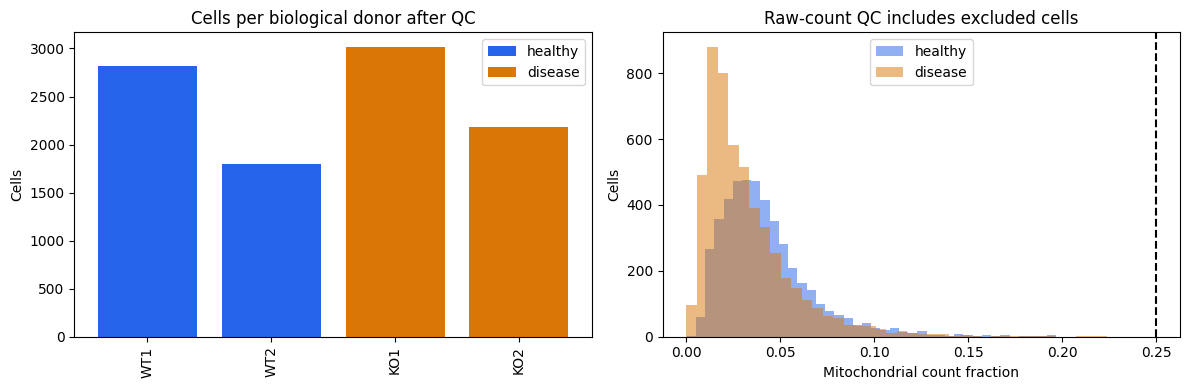

In [5]:
donors = external.obs.groupby(['donor_group', 'condition'], observed=True).size().rename('cells').reset_index()
display(donors)
print('Independent donor entries by condition:')
display(donors.groupby('condition', observed=True).size().rename('donors').to_frame())
confounding = pd.crosstab(external.obs.technical_batch, external.obs.condition)
confounding.to_csv(DEST / 'condition_by_technical_batch.csv')
display(confounding)
columns = [c for c in ['donor_id', 'condition', 'technical_batch', 'assay', 'suspension_type',
                       'sex', 'development_stage', 'Age_in_days', 'sacrifice_day',
                       'experimental_group', 'sample_id', 'tamoxifen_start_day'] if c in external.obs]
sample_audit = external.obs[columns].drop_duplicates().sort_values(['condition', 'donor_id'])
sample_audit.to_csv(DEST / 'sample_covariates.csv', index=False)
display(sample_audit)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for condition, color in [('healthy', '#2563eb'), ('disease', '#d97706')]:
    group = donors.loc[donors.condition == condition]
    axes[0].bar(group.donor_group.str.rsplit(':').str[-1], group.cells, color=color, label=condition)
axes[0].set(title='Cells per biological donor after QC', ylabel='Cells')
axes[0].tick_params(axis='x', rotation=90)
axes[0].legend()
for condition, color in [('healthy', '#2563eb'), ('disease', '#d97706')]:
    values = qc.loc[qc.condition == condition, 'qc_mito_fraction']
    axes[1].hist(values, bins=40, alpha=.5, color=color, label=condition)
axes[1].axvline(MAX_MITO_FRACTION, color='black', linestyle='--')
axes[1].set(title='Raw-count QC includes excluded cells', xlabel='Mitochondrial count fraction', ylabel='Cells')
axes[1].legend()
fig.tight_layout()
fig.savefig(DEST / 'donor_and_qc_audit.png', dpi=160)
plt.show()


## 5. Check protein coverage and create the full augmented inputs

Use the existing mouse ESMC600 embedding dictionary. The trusted local `.pt` is loaded on CPU with `weights_only=True` to audit coverage.

`exploration.csv` contains all original atlas cells plus every retained study WT and knockout cell. **This is the source for the first experiment:** apply the existing 90/10 species-stratified cell split before fitted preprocessing and training. All five species receive derived normalized-expression copies; original atlas files remain untouched. A fit on the entire exploration population would instead be transductive. `external_prepared.h5ad` retains study raw counts separately.

The notebook also writes donor-fold assignments and the selected fold's files for an **optional later animal-holdout experiment**. Those fold files are not used in the first run. New preparation settings need a fresh destination. Disease/source/donor annotations are post-hoc metadata and must not enter the label-free artifact.


In [ ]:
import torch
embedding_path = ROOT / manifest.loc[manifest.species == 'm_musculus', 'embedding_path'].iloc[0]
protein = torch.load(embedding_path, map_location='cpu', weights_only=True)
protein_genes = {str(g).lower() for g in protein}
covered = external.var_names.str.lower().isin(protein_genes)
protein_audit = pd.DataFrame({'gene': external.var_names, 'has_protein_embedding': covered})
protein_audit.to_csv(DEST / 'protein_coverage.csv', index=False)
print('Mouse shared genes with protein embeddings:', int(covered.sum()), '/', len(covered))
assert covered.mean() >= .8, 'Review substantial protein coverage loss'
del protein
gc.collect()
combined_obs, folds = materialize_experiment(
    MANIFEST, external, DEST, root=ROOT, seed=SEED, config=config,
    materialize_folds=MATERIALIZE_FOLDS,
)
display(pd.read_csv(DEST / 'composition.csv'))
fold_summary = folds.groupby(['fold', 'split', 'condition'], observed=True).agg(
    donors=('donor_group', 'nunique'), cells=('obs_id', 'size')).reset_index()
fold_summary.to_csv(DEST / 'fold_summary.csv', index=False)
display(fold_summary)
for fold, frame in folds.groupby('fold'):
    train_groups = set(frame.loc[frame.split == 'train', 'donor_group'])
    test_groups = set(frame.loc[frame.split == 'test', 'donor_group'])
    assert not train_groups & test_groups
    assert frame.groupby('donor_group', observed=True)['split'].nunique().eq(1).all()
assert folds.loc[folds.split == 'test', 'obs_id'].value_counts().eq(1).all()
assert set(combined_obs.species) == {'m_musculus'}
assert len(combined_obs) == 26947 + external.n_obs
for fold in MATERIALIZE_FOLDS:
    train_manifest = pd.read_csv(DEST / f'fold_{fold}/train.csv')
    assert len(train_manifest) == 5 and set(train_manifest.species) == set(manifest.species)
    test = ad.read_h5ad(DEST / f'fold_{fold}/m_musculus_test.h5ad', backed='r')
    train_mouse = ad.read_h5ad(DEST / f'fold_{fold}/m_musculus_train.h5ad', backed='r')
    assert 'NOT raw counts' in test.uns['expression_scale']
    assert 'NOT raw counts' in train_mouse.uns['expression_scale']
    assert not set(test.obs_names) & set(train_mouse.obs_names)
    assert set(test.obs.donor_group) == set(folds.loc[(folds.fold == fold) & (folds.split == 'test'), 'donor_group'])
    train_mouse.file.close(); test.file.close()
print('First experiment: full source manifest for 90/10 cell split:', DEST / 'exploration.csv')
print('Optional later donor-holdout training manifest:', DEST / 'fold_0/train.csv')
print('Prepared held-out mouse normalized expression:', DEST / 'fold_0/m_musculus_test.h5ad')
print('Post-hoc metadata join:', DEST / 'evaluation_metadata.csv.gz')


## 6. First experiment handoff

Run a fresh shared foundation and **the supervised cell-type baseline plus InfoNCE only** on the full augmented five-species input, retaining the existing 90/10 cell holdout. Use seed 0, 200 macrogenes, 256 hidden/embedding dimensions, 2,000 HVGs, 20 pretraining epochs, 30 epochs for each fine-tuning method, batch 512 and FP32. This preparation notebook does not start training or cloud compute.

For GCP, `scripts/prepare_disease_cloud_inputs.py` makes a checksum-verified portable copy under `data/`. Source `experiments/hmmff_rdeb_skin_cell_holdout.env` and follow the [canonical runbook](../../GCP_RUNBOOK.md#rdeb-skin-disease-experiment). The dedicated [disease report notebook](../jax/human_monkey_mouse_frog_fish_rdeb_skin_holdout.ipynb) reads completed artifacts and compares pretraining, baseline and InfoNCE using training-fitted UMAPs and held-out `transform`.

First inspect skin keratinocytes: atlas reference, study WT and study knockout, with source, donor and raw QC colourings. Fibroblasts support a within-study comparison because the original mouse skin subset lacks a fibroblast reference. A continuous shift, a source effect or no clear disease separation are valid exploratory outcomes. Keep the original integration and cell-type metrics.

Model inputs are normalized expression; the inherited ZINB likelihood is a compatibility surrogate. The cell split can expose the same animal on both sides and does not establish unseen-animal generalization. Whole-animal holdouts, PCA/probes, marker programmes, extra seeds and ablations belong to the [optional later validation](DISEASE_VALIDATION_FOLLOWUP.md).


In [7]:
import importlib.metadata
versions = {name: importlib.metadata.version(name) for name in
            ['anndata', 'numpy', 'pandas', 'scipy', 'h5py', 'matplotlib', 'torch', 'nbformat']}
execution = {'executed_at_utc': datetime.now(timezone.utc).isoformat(),
             'python': platform.python_version(), 'packages': versions,
             'live_api': LIVE_API, 'preset': PRESET,
             'source_download_sha256': sha256(raw_path),
             'prepared_external_cells': external.n_obs, 'shared_mouse_genes': external.n_vars,
             'original_five_atlas_cells': int(atlas_audit.cells.sum()),
             'augmented_five_species_cells': int(atlas_audit.cells.sum()) + external.n_obs,
             'materialized_folds': list(MATERIALIZE_FOLDS),
             'preparation_record_sha256': sha256(DEST / 'preparation_record.json')}
write_json(DEST / 'notebook_execution.json', execution)
display(pd.Series(execution, name='Local execution record'))


executed_at_utc                                  2026-11-03T11:44:19.819552+00:00
python                                                                    3.10.20
packages                        {'anndata': '0.11.4', 'numpy': '1.26.4', 'pand...
live_api                                                                     True
preset                                                                  rdeb_skin
source_download_sha256          74d0d79ad6b44af4f0c2b4d5df726600b4017444bbdd1c...
prepared_external_cells                                                      9816
shared_mouse_genes                                                          15316
original_five_atlas_cells                                                  148727
augmented_five_species_cells                                               158543
materialized_folds                                                            [0]
preparation_record_sha256       780228119295325b0b9c6e8d5b332110054895032ecbed...
Name: Local exec